# Task 5 Commercial Replacement Verification: Face Detection & Face Recognition

**Repo:** `f:\IRIS\surveillance-new`  
**Task 5A (Face Detection) Rank 1 Candidate:** `qualcomm/Lightweight-Face-Detection` (`face_det_lite`, **BSD-3-Clause**)  
**Task 5B (Face Recognition) Rank 1 Candidate:** `fal/AuraFace-v1` (`glintr100.onnx` **ONLY**, **Apache-2.0**)  
*(Important license note: `fal/AuraFace-v1` also bundles `scrfd_10g_bnkps.onnx`, `1k3d68.onnx`, `2d106det.onnx`, and `genderage.onnx` which derive from InsightFace non-commercial models — this notebook downloads and runs **only `glintr100.onnx`**.)*

### What this notebook verifies
1. **Isolated downloads:** Uses only `notebooks/downloads/` (`models_cache/`, `onnx_exports/`) without touching repo locks or InsightFace DVC packs.
2. **Task 5A (`face_det_lite`):** Runs raw `[1, 1, 480, 640]` grayscale inference on real `calib_images/*.jpg` surveillance frames and inspects `heatmap`, `bbox`, and 5-point `landmark` (`[x0..x4, y0..y4]`) outputs.
3. **DeepStream SGIE ONNX Wrapper:** Patches `face_det_lite` to dynamic batch (`batch=1..16`), wraps it with BT.601 RGB-to-Gray + CenterNet peak/box/landmark decode into `[batch, 4800, 15]` matching `config_sgie_face.txt` (`model-color-format=0`, `net-scale-factor=1/255`) and `nvdsparseface_Yolo.cpp` (`NvDsInferParseYoloFace`) **with zero C++ parser rewrite**.
4. **IRIS `face_detect` Integration:** Simulates `nvdsparseface_Yolo.cpp` + `InstanceMask` + `perception.modules.face_detect.face_landmarks_raw`, `landmarks_to_capture`, and `FaceDetect.transform` / `analyze` on person crops.
5. **Task 5B (`AuraFace-v1 glintr100.onnx`):** Verifies Apache-2.0 weight isolation, standalone OpenCV 5-point affine `norm_crop` (`112x112`, eliminating `insightface.app.FaceAnalysis` dependency), ORT CUDA `batch=1` & `batch=16` latency, and same-ID vs cross-ID cosine separation.


In [1]:
import os
import sys
import glob
import math
import time
import urllib.request
import zipfile
from pathlib import Path

# Keep ALL HuggingFace / model downloads inside notebooks/downloads/
REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DOWNLOADS_DIR = REPO_ROOT / "notebooks" / "downloads"
MODELS_CACHE = DOWNLOADS_DIR / "models_cache"
ONNX_DIR = DOWNLOADS_DIR / "onnx_exports"
HF_CACHE = MODELS_CACHE / "hf"
for p in (DOWNLOADS_DIR, MODELS_CACHE, ONNX_DIR, HF_CACHE):
    p.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(HF_CACHE)
os.environ["HUGGINGFACE_HUB_CACHE"] = str(HF_CACHE / "hub")
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

# Import torch BEFORE onnxruntime so Windows resolves CUDA/cuBLAS DLLs from torch/lib
import torch
import onnx
import onnxruntime as ort
import cv2
import numpy as np
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("ONNX:", onnx.__version__, "| ONNX Runtime:", ort.__version__, "| Providers:", ort.get_available_providers())
print("Downloads root:", DOWNLOADS_DIR)


F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.6
PyTorch: 2.14.1+cu130 | CUDA available: True
GPU: Quadro RTX 3000
ONNX: 1.23.2 | ONNX Runtime: 1.32.0 | Providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Downloads root: F:\IRIS\surveillance-new\notebooks\downloads


## 1. Acquire `qualcomm/Lightweight-Face-Detection` (`face_det_lite`, BSD-3-Clause) & Raw Inference
Raw exported Qualcomm `face_det_lite-onnx-float` expects:
- `input`: `[1, 1, 480, 640]` float32 **grayscale** `[0.0, 1.0]`
- Outputs: `heatmap [1, 1, 60, 80]`, `bbox [1, 4, 60, 80]`, `landmark [1, 10, 60, 80]` (stride 8; landmark channels packed as `[x0..x4, y0..y4]`).


In [2]:
FD_DIR = MODELS_CACHE / "face_det_lite" / "face_det_lite-onnx-float"
FD_ONNX = FD_DIR / "face_det_lite.onnx"
FD_ZIP_URL = "https://qaihub-public-assets.s3.us-west-2.amazonaws.com/qai-hub-models/models/face_det_lite/releases/v0.66.0/face_det_lite-onnx-float.zip"

if not FD_ONNX.exists():
    zip_path = MODELS_CACHE / "face_det_lite" / "face_det_lite-onnx-float.zip"
    zip_path.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading face_det_lite-onnx-float.zip ...")
    urllib.request.urlretrieve(FD_ZIP_URL, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(MODELS_CACHE / "face_det_lite")
    zip_path.unlink(missing_ok=True)

fd_raw_model = onnx.load(str(FD_ONNX), load_external_data=False)
print("Raw face_det_lite opset:", [o.version for o in fd_raw_model.opset_import], "| IR:", fd_raw_model.ir_version)
print("Raw inputs :", [(i.name, [d.dim_value or d.dim_param for d in i.type.tensor_type.shape.dim]) for i in fd_raw_model.graph.input])
print("Raw outputs:", [(o.name, [d.dim_value or d.dim_param for d in o.type.tensor_type.shape.dim]) for o in fd_raw_model.graph.output])
print("Reshape nodes in raw graph:", sum(1 for n in fd_raw_model.graph.node if n.op_type == "Reshape"))

sess_raw_fd = ort.InferenceSession(str(FD_ONNX), providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
print("Raw ORT active providers:", sess_raw_fd.get_providers())

calib_paths = sorted(glob.glob(str(REPO_ROOT / "perception" / "models" / "DeepStream-Yolo" / "calib_images" / "*.jpg")))
assert len(calib_paths) > 0, "No calibration images found"

def letterbox_rgb(bgr: np.ndarray, tw: int = 640, th: int = 480):
    h, w = bgr.shape[:2]
    scale = min(tw / w, th / h)
    nw, nh = int(round(w * scale)), int(round(h * scale))
    dx, dy = (tw - nw) // 2, (th - nh) // 2
    rgb_resized = cv2.resize(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), (nw, nh), interpolation=cv2.INTER_LINEAR)
    canvas = np.zeros((th, tw, 3), dtype=np.uint8)
    canvas[dy:dy+nh, dx:dx+nw] = rgb_resized
    return canvas, scale, dx, dy

def decode_raw_face_det_lite(hm, box, lmk, thresh=0.35, stride=8.0):
    prob = 1.0 / (1.0 + np.exp(-hm[0, 0]))
    t_hm = torch.from_numpy(prob)[None, None]
    peaks = (t_hm == torch.nn.functional.max_pool2d(t_hm, 3, 1, 1))[0, 0].numpy() * prob
    ys, xs = np.where(peaks >= thresh)
    dets = []
    for cy, cx in zip(ys, xs):
        sc = float(peaks[cy, cx])
        l, t, r, b = box[0, :, cy, cx]
        xyxy = [(cx - l) * stride, (cy - t) * stride, (cx + r) * stride, (cy + b) * stride]
        lm = lmk[0, :, cy, cx]
        pts_net = np.stack([(lm[:5] + cx) * stride, (lm[5:] + cy) * stride], axis=1)
        dets.append((sc, xyxy, pts_net))
    dets.sort(key=lambda z: -z[0])
    return dets

sample_imgs = ["frame_00005.jpg", "frame_00006.jpg", "frame_00021.jpg", "frame_00022.jpg", "frame_00026.jpg"]
raw_results = {}
for fn in sample_imgs:
    bgr = cv2.imread(str(REPO_ROOT / "perception" / "models" / "DeepStream-Yolo" / "calib_images" / fn))
    canvas_rgb, sc, dx, dy = letterbox_rgb(bgr)
    rgb01 = canvas_rgb.astype(np.float32) / 255.0
    gray01 = (0.299 * rgb01[:, :, 0] + 0.587 * rgb01[:, :, 1] + 0.114 * rgb01[:, :, 2]).astype(np.float32)
    hm, box, lmk = sess_raw_fd.run(None, {"input": gray01[None, None]})
    dets = decode_raw_face_det_lite(hm, box, lmk, thresh=0.40)
    raw_results[fn] = dets
    print(f"{fn}: {len(dets)} faces >= 0.40 | scores={[round(d[0], 3) for d in dets]}")


Raw face_det_lite opset: [21] | IR: 10
Raw inputs : [('input', [1, 1, 480, 640])]
Raw outputs: [('heatmap', [1, 1, 60, 80]), ('bbox', [1, 4, 60, 80]), ('landmark', [1, 10, 60, 80])]
Reshape nodes in raw graph: 0
Raw ORT active providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']


frame_00005.jpg: 2 faces >= 0.40 | scores=[0.74, 0.675]
frame_00006.jpg: 2 faces >= 0.40 | scores=[0.671, 0.566]
frame_00021.jpg: 4 faces >= 0.40 | scores=[0.703, 0.636, 0.6, 0.424]
frame_00022.jpg: 3 faces >= 0.40 | scores=[0.739, 0.723, 0.489]
frame_00026.jpg: 1 faces >= 0.40 | scores=[0.668]


## 2. Export DeepStream-Compatible `face_det_lite` Wrapper ONNX (`[batch, 3, 480, 640]` -> `[batch, 4800, 15]`)
To drop cleanly into `config_sgie_face.txt` + `nvdsparseface_Yolo.cpp` (`NvDsInferParseYoloFace`):
- **Input mismatch resolved:** Raw `face_det_lite.onnx` takes static `[1, 1, 480, 640]` grayscale, whereas `config_sgie_face.txt` sends `batch-size=16`, RGB `[0, 1]` (`model-color-format=0`, `net-scale-factor=1/255`). Because the backbone has `0` `Reshape` nodes, patching dim 0 to `'batch'` + prepending BT.601 luma works for `batch=1..16`.
- **Output mismatch resolved:** `nvdsparseface_Yolo.cpp` reads `[N, 15]` rows (`[x1, y1, x2, y2, score, lm0x, lm0y, ..., lm4x, lm4y]`). Appending a small ONNX decode block converts `(heatmap, bbox, landmark)` into `['batch', 4800, 15]`.


In [3]:
import torch.nn as nn
from onnx import compose

class PreRgbToGray(nn.Module):
    def forward(self, images: torch.Tensor) -> torch.Tensor:
        w = images.new_tensor([0.299, 0.587, 0.114]).view(1, 3, 1, 1)
        return (images * w).sum(dim=1, keepdim=True)

class PostDecodeYoloFace(nn.Module):
    def __init__(self, h: int = 60, w: int = 80, stride: float = 8.0):
        super().__init__()
        gy, gx = torch.meshgrid(torch.arange(h, dtype=torch.float32), torch.arange(w, dtype=torch.float32), indexing="ij")
        self.register_buffer("gx", gx.view(1, 1, h, w))
        self.register_buffer("gy", gy.view(1, 1, h, w))
        self.stride = stride

    def forward(self, heatmap: torch.Tensor, bbox: torch.Tensor, landmark: torch.Tensor) -> torch.Tensor:
        prob = torch.sigmoid(heatmap)
        pooled = torch.nn.functional.max_pool2d(prob, kernel_size=3, stride=1, padding=1)
        score = prob * (prob >= pooled).to(prob.dtype)
        x1 = (self.gx - bbox[:, 0:1]) * self.stride
        y1 = (self.gy - bbox[:, 1:2]) * self.stride
        x2 = (self.gx + bbox[:, 2:3]) * self.stride
        y2 = (self.gy + bbox[:, 3:4]) * self.stride
        lms = []
        for k in range(5):
            lms.extend([
                (self.gx + landmark[:, k:k+1]) * self.stride,
                (self.gy + landmark[:, k+5:k+6]) * self.stride,
            ])
        return torch.cat([x1, y1, x2, y2, score, *lms], dim=1).flatten(2).transpose(1, 2).contiguous()

# Patch core face_det_lite batch dimension from static 1 -> symbolic 'batch'
core_model = onnx.load(str(FD_ONNX), load_external_data=True)
for t in list(core_model.graph.input) + list(core_model.graph.output) + list(core_model.graph.value_info):
    dims = t.type.tensor_type.shape.dim
    if len(dims) == 4 and dims[0].dim_value == 1:
        dims[0].ClearField("dim_value")
        dims[0].dim_param = "batch"

tmp_pre = ONNX_DIR / "_tmp_fd_pre.onnx"
tmp_post = ONNX_DIR / "_tmp_fd_post.onnx"
torch.onnx.export(PreRgbToGray().eval(), (torch.zeros(1, 3, 480, 640),), str(tmp_pre),
                  input_names=["images"], output_names=["input"],
                  dynamic_axes={"images": {0: "batch"}, "input": {0: "batch"}}, opset_version=18, dynamo=False)
torch.onnx.export(PostDecodeYoloFace().eval(),
                  (torch.zeros(1, 1, 60, 80), torch.zeros(1, 4, 60, 80), torch.zeros(1, 10, 60, 80)), str(tmp_post),
                  input_names=["heatmap", "bbox", "landmark"], output_names=["output"],
                  dynamic_axes={"heatmap": {0: "batch"}, "bbox": {0: "batch"}, "landmark": {0: "batch"}, "output": {0: "batch"}},
                  opset_version=18, dynamo=False)

pre_m = onnx.version_converter.convert_version(onnx.load(str(tmp_pre)), core_model.opset_import[0].version)
post_m = onnx.version_converter.convert_version(onnx.load(str(tmp_post)), core_model.opset_import[0].version)
pre_m.ir_version = core_model.ir_version
post_m.ir_version = core_model.ir_version

merged = compose.merge_models(compose.add_prefix(pre_m, "pre_"), core_model, io_map=[("pre_input", "input")])
merged = compose.merge_models(merged, compose.add_prefix(post_m, "post_"),
                              io_map=[("heatmap", "post_heatmap"), ("bbox", "post_bbox"), ("landmark", "post_landmark")])
merged.graph.input[0].name = "images"
for node in merged.graph.node:
    for i, name in enumerate(node.input):
        if name == "pre_images":
            node.input[i] = "images"
merged.graph.output[0].name = "output"
for node in merged.graph.node:
    for i, name in enumerate(node.output):
        if name == "post_output":
            node.output[i] = "output"

# Pin output dims [batch, 4800, 15] explicitly for TensorRT / nvdsparseface_Yolo.cpp metadata
out_dims = merged.graph.output[0].type.tensor_type.shape.dim
out_dims[0].ClearField("dim_value"); out_dims[0].dim_param = "batch"
out_dims[1].ClearField("dim_param"); out_dims[1].dim_value = 4800
out_dims[2].ClearField("dim_param"); out_dims[2].dim_value = 15

DS_FD_ONNX = ONNX_DIR / "face_det_lite_deepstream_rgb_b16.onnx"
onnx.save(merged, str(DS_FD_ONNX))
tmp_pre.unlink(missing_ok=True)
tmp_post.unlink(missing_ok=True)
onnx.checker.check_model(str(DS_FD_ONNX))

sess_ds_fd = ort.InferenceSession(str(DS_FD_ONNX), providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
print("Saved DeepStream ONNX:", DS_FD_ONNX.name, f"({DS_FD_ONNX.stat().st_size / 1024 / 1024:.2f} MB)")
print("DS ONNX input :", [(i.name, i.shape) for i in sess_ds_fd.get_inputs()])
print("DS ONNX output:", [(o.name, o.shape) for o in sess_ds_fd.get_outputs()])

# Numeric parity check vs raw face_det_lite on frame_00005.jpg
bgr5 = cv2.imread(str(REPO_ROOT / "perception" / "models" / "DeepStream-Yolo" / "calib_images" / "frame_00005.jpg"))
c5, _, _, _ = letterbox_rgb(bgr5)
x_rgb = (c5.astype(np.float32) / 255.0).transpose(2, 0, 1)[None]
ds_out = sess_ds_fd.run(None, {"images": x_rgb})[0][0]
raw_top = raw_results["frame_00005.jpg"][0]
wrapped_rows = ds_out[ds_out[:, 4] >= 0.40]
wrapped_top = wrapped_rows[np.argmax(wrapped_rows[:, 4])]
box_diff = np.max(np.abs(wrapped_top[:4] - np.array(raw_top[1])))
score_diff = abs(float(wrapped_top[4]) - raw_top[0])
lm_diff = np.max(np.abs(wrapped_top[5:].reshape(5, 2) - raw_top[2]))
print(f"Parity vs raw face_det_lite -> max box diff={box_diff:.2e}px | score diff={score_diff:.2e} | max lm diff={lm_diff:.2e}px")
assert box_diff < 1e-3 and score_diff < 1e-5 and lm_diff < 1e-3

# Latency benchmark on CUDAExecutionProvider (batch=1 and batch=16)
def bench_ort(sess, input_name, shape, runs=30):
    dummy = np.random.rand(*shape).astype(np.float32)
    for _ in range(5):
        sess.run(None, {input_name: dummy})
    t0 = time.perf_counter()
    for _ in range(runs):
        sess.run(None, {input_name: dummy})
    ms = (time.perf_counter() - t0) * 1000.0 / runs
    return ms

ms_b1 = bench_ort(sess_ds_fd, "images", (1, 3, 480, 640), runs=40)
ms_b16 = bench_ort(sess_ds_fd, "images", (16, 3, 480, 640), runs=20)
print(f"ORT CUDA latency -> batch=1: {ms_b1:.2f} ms ({1000/ms_b1:.1f} FPS) | batch=16: {ms_b16:.2f} ms/batch ({ms_b16/16:.2f} ms/face-crop)")


C:\Users\Maha Mamdouh\AppData\Local\Temp\ipykernel_19388\4032243400.py:43: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(PreRgbToGray().eval(), (torch.zeros(1, 3, 480, 640),), str(tmp_pre),
C:\Users\Maha Mamdouh\AppData\Local\Temp\ipykernel_19388\4032243400.py:46: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
 

Saved DeepStream ONNX: face_det_lite_deepstream_rgb_b16.onnx (3.65 MB)
DS ONNX input : [('images', ['batch', 3, 480, 640])]
DS ONNX output: [('output', ['batch', 4800, 15])]
Parity vs raw face_det_lite -> max box diff=9.54e-06px | score diff=0.00e+00 | max lm diff=2.29e-05px


ORT CUDA latency -> batch=1: 6.09 ms (164.3 FPS) | batch=16: 38.17 ms/batch (2.39 ms/face-crop)


## 3. IRIS `nvdsparseface_Yolo.cpp` + `perception.modules.face_detect` Integration Check
Here we feed the `[4800, 15]` tensor from the DeepStream wrapper on simulated SGIE `person` crops into:
1. A bit-exact mirror of `perception/models/DeepStream-Yolo-Face/nvdsinfer_custom_impl_Yolo_face/nvdsparseface_Yolo.cpp` (`decodeTensorYoloFace`, `addFaceProposal`, `NMS_THRESH = 0.45`)
2. Real repo code: `InstanceMask`, `face_landmarks_raw`, `landmarks_to_capture`, and `FaceDetect.transform()` / `analyze()`.


SGIE person crop (420, 120, 560, 580) -> NvDsInferParseYoloFace kept 3 faces
FaceDetect kept faces: 3 | out.fields['faces']: [(833.326737721761, 360.8263498942057, 55.410203297932945, 75.39896011352539, 0.822, 101), (504.6103998819987, 246.0495255788167, 36.40996551513672, 51.668806076049805, 0.743, 101), (629.4934272766113, 347.45569610595703, 32.51064936319987, 56.34860865275065, 0.466, 101)]
  owner=101 conf=0.822 box=[833.3, 360.8, 55.4, 75.4] eyes_y=390.0,391.8 mouth_y=415.7,417.2
  owner=101 conf=0.743 box=[504.6, 246.0, 36.4, 51.7] eyes_y=267.0,268.0 mouth_y=284.5,285.5
  owner=101 conf=0.466 box=[629.5, 347.5, 32.5, 56.3] eyes_y=370.4,373.7 mouth_y=388.5,391.4


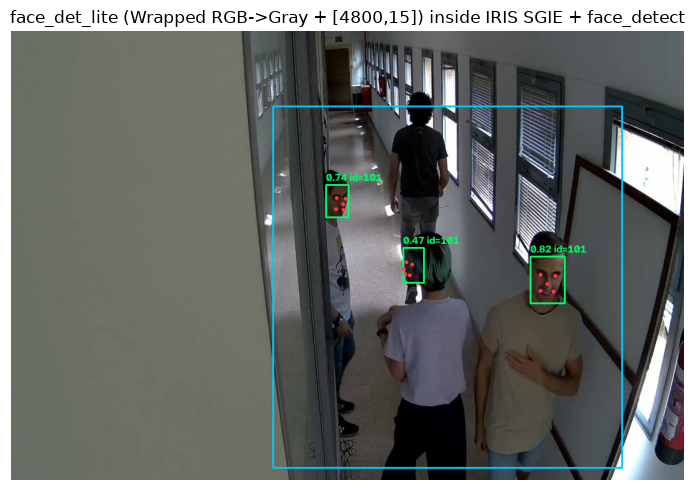

In [4]:
from perception.engine.frame import FrameOutput, FrameView, ObjectView
from perception.engine.modules import EngineServices
from perception.engine.nvds import InstanceMask
from perception.modules import face_detect as fd_mod

def nvdsparse_yolo_face_cpp_mirror(output_tensor: np.ndarray, net_w: int = 640, net_h: int = 480,
                                   precluster_thresh: float = 0.25, nms_thresh: float = 0.45):
    """Exact mirror of nvdsparseface_Yolo.cpp: decodeTensorYoloFace + addFaceProposal + NMS."""
    rows, channels = output_tensor.shape
    assert channels == 15, f"Expected 15 channels, got {channels}"
    candidates = []
    for n in range(rows):
        score = float(output_tensor[n, 4])
        if score < precluster_thresh:
            continue
        x1 = max(0.0, min(float(net_w), float(output_tensor[n, 0])))
        y1 = max(0.0, min(float(net_h), float(output_tensor[n, 1])))
        x2 = max(0.0, min(float(net_w), float(output_tensor[n, 2])))
        y2 = max(0.0, min(float(net_h), float(output_tensor[n, 3])))
        w, h = max(0.0, min(float(net_w), x2 - x1)), max(0.0, min(float(net_h), y2 - y1))
        if w < 1.0 or h < 1.0:
            continue
        mask_vals = np.zeros(15, dtype=np.float32)
        for p in range(5):
            mask_vals[p * 3 + 0] = max(0.0, min(float(net_w), float(output_tensor[n, p * 2 + 5])))
            mask_vals[p * 3 + 1] = max(0.0, min(float(net_h), float(output_tensor[n, p * 2 + 6])))
            mask_vals[p * 3 + 2] = 1.0
        candidates.append((score, (x1, y1, w, h), InstanceMask(values=mask_vals, width=net_w, height=net_h, threshold=0.0)))

    candidates.sort(key=lambda c: -c[0])
    keep = []
    for cand in candidates:
        bx1, by1, bw1, bh1 = cand[1]
        ok = True
        for k in keep:
            bx2, by2, bw2, bh2 = k[1]
            ix1, iy1 = max(bx1, bx2), max(by1, by2)
            ix2, iy2 = min(bx1 + bw1, bx2 + bw2), min(by1 + bh1, by2 + bh2)
            inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
            union = bw1 * bh1 + bw2 * bh2 - inter
            if union > 0 and (inter / union) > nms_thresh:
                ok = False
                break
        if ok:
            keep.append(cand)
    return keep

# Simulate an SGIE person crop inside frame_00005.jpg (mux_size == capture_size = 1080x720)
H, W = bgr5.shape[:2]
person_box = (420, 120, 560, 580)  # upper-to-full body crop covering visible faces in frame_00005.jpg
px, py, pw, ph = person_box
crop_bgr = bgr5[py:py+ph, px:px+pw]
crop_canvas, sc_c, dx_c, dy_c = letterbox_rgb(crop_bgr, tw=640, th=480)
x_crop = (crop_canvas.astype(np.float32) / 255.0).transpose(2, 0, 1)[None]
crop_raw_out = sess_ds_fd.run(None, {"images": x_crop})[0][0]
parsed = nvdsparse_yolo_face_cpp_mirror(crop_raw_out, net_w=640, net_h=480, precluster_thresh=0.25)
print(f"SGIE person crop {person_box} -> NvDsInferParseYoloFace kept {len(parsed)} faces")
assert len(parsed) >= 1

svc = EngineServices(
    redis=None, redis_factory=lambda: None, emit=lambda *a, **k: True, request_clip=lambda *a, **k: None,
    stream_ids=["cam-1"], timer=lambda i, f: None, telemetry=None, mux_size=(W, H), index_to_id={0: "cam-1"},
    engine=type("E", (), {"pipeline_preview": False, "infer_interval": 1, "sample_interval": 0.1})(),
)
fd_module = fd_mod.FaceDetect(fd_mod.Settings(confidence_threshold=0.25, min_pixels=24, landmarks=True), svc)

# Map parsed SGIE face boxes from 640x480 letterbox into mux coords (matching nvinfer SGIE output)
objs = [ObjectView(101, "person", 0.92, 0.92, *person_box, raw=object())]
for score, (fx, fy, fw, fh), inst_mask in parsed:
    mx = px + (fx - dx_c) / sc_c
    my = py + (fy - dy_c) / sc_c
    mw = fw / sc_c
    mh = fh / sc_c
    f_obj = ObjectView(0, "face", score, score, mx, my, mw, mh, draw=False, publish=False)
    f_obj.attrs["landmarks_raw"] = fd_mod.face_landmarks_raw(inst_mask)
    objs.append(f_obj)

frame = FrameView(stream_id="cam-1", state=None, pad_index=0, frame_num=5, pts=0.2, now=0.2,
                  buf_pts=200_000_000, need_meta=True, mux_size=(W, H), capture_size=(W, H), bgr=bgr5)
frame.objects = objs
fd_module.transform(frame)
out = FrameOutput()
fd_module.analyze(frame, out)

face_objs = [o for o in frame.objects if o.kind == "face"]
print("FaceDetect kept faces:", len(face_objs), "| out.fields['faces']:", out.fields.get("faces"))
for fo in face_objs:
    pts_cap = fo.attrs.get("landmarks")
    assert fo.parent_id == 101 and pts_cap is not None and len(pts_cap) == 5
    # Anatomical sanity: eyes above mouth in image y
    assert max(pts_cap[0][1], pts_cap[1][1]) < min(pts_cap[3][1], pts_cap[4][1])
    print(f"  owner={fo.parent_id} conf={fo.conf:.3f} box={[round(v,1) for v in fo.bbox]} eyes_y={pts_cap[0][1]:.1f},{pts_cap[1][1]:.1f} mouth_y={pts_cap[3][1]:.1f},{pts_cap[4][1]:.1f}")

# Visualize frame_00005.jpg detections from the SGIE simulation
vis = cv2.cvtColor(bgr5.copy(), cv2.COLOR_BGR2RGB)
cv2.rectangle(vis, (px, py), (px+pw, py+ph), (0, 200, 255), 2)
for fo in face_objs:
    x, y, w, h = [int(round(v)) for v in fo.bbox]
    cv2.rectangle(vis, (x, y), (x+w, y+h), (0, 255, 100), 2)
    cv2.putText(vis, f"{fo.conf:.2f} id={fo.parent_id}", (x, max(15, y-6)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 100), 2)
    for lx, ly in fo.attrs["landmarks"]:
        cv2.circle(vis, (int(round(lx)), int(round(ly))), 3, (255, 60, 60), -1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(vis); ax.axis("off")
ax.set_title("face_det_lite (Wrapped RGB->Gray + [4800,15]) inside IRIS SGIE + face_detect")
plt.tight_layout(); plt.show()


## 4. Acquire `fal/AuraFace-v1` (`glintr100.onnx` ONLY, Apache-2.0) & License Check
- Downloads **only `glintr100.onnx`** (ResNet-100 ArcFace trained on commercial/public data, Apache-2.0).
- Confirms none of the InsightFace non-commercial ONNX companions (`scrfd_10g_bnkps.onnx`, `1k3d68.onnx`, `2d106det.onnx`, `genderage.onnx`) are downloaded or loaded.
- Shows why `perception/insightface_pack.py` + `perception/modules/face_recognition/recognizer.py` cannot keep using `insightface.app.FaceAnalysis`: we run `glintr100.onnx` directly via `onnxruntime` + OpenCV 5-point `norm_crop` (`cv2.estimateAffinePartial2D`).


In [5]:
AF_GLINT_PATH = Path(hf_hub_download("fal/AuraFace-v1", "glintr100.onnx"))
snap_files = sorted(p.name for p in AF_GLINT_PATH.parent.iterdir() if p.suffix == ".onnx")
print("AuraFace snapshot ONNX files:", snap_files)
FORBIDDEN_NC = {"scrfd_10g_bnkps.onnx", "1k3d68.onnx", "2d106det.onnx", "genderage.onnx"}
assert snap_files == ["glintr100.onnx"], f"Unexpected ONNX files present: {snap_files}"
assert not (FORBIDDEN_NC & set(snap_files))

# Patch output '1333' dim 0 from static 1 -> dynamic 'batch' in an exported copy so ORT emits zero batch>1 warnings
af_model = onnx.load(str(AF_GLINT_PATH))
out_dim0 = af_model.graph.output[0].type.tensor_type.shape.dim[0]
out_dim0.ClearField("dim_value")
out_dim0.dim_param = "batch"
AF_DYN_ONNX = ONNX_DIR / "auraface_glintr100_dyn_b16.onnx"
onnx.save(af_model, str(AF_DYN_ONNX))

sess_af = ort.InferenceSession(str(AF_DYN_ONNX), providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
print("AuraFace ONNX input :", [(i.name, i.shape) for i in sess_af.get_inputs()])
print("AuraFace ONNX output:", [(o.name, o.shape) for o in sess_af.get_outputs()])

af_ms_b1 = bench_ort(sess_af, "data", (1, 3, 112, 112), runs=40)
af_ms_b16 = bench_ort(sess_af, "data", (16, 3, 112, 112), runs=20)
print(f"AuraFace ORT CUDA latency -> batch=1: {af_ms_b1:.2f} ms | batch=16: {af_ms_b16:.2f} ms/batch ({af_ms_b16/16:.2f} ms/face)")


AuraFace snapshot ONNX files: ['glintr100.onnx']


AuraFace ONNX input : [('data', ['None', 3, 112, 112])]
AuraFace ONNX output: [('1333', ['batch', 512])]


AuraFace ORT CUDA latency -> batch=1: 14.15 ms | batch=16: 85.88 ms/batch (5.37 ms/face)


## 5. End-to-End 5A -> 5B Pipeline Verification (Standalone 5-Point Alignment + Similarity Separation)
We extract detected faces across multiple `calib_images` frames (`frame_00005.jpg`, `frame_00006.jpg`, `frame_00021.jpg`, `frame_00022.jpg`, `frame_00026.jpg`), align each with OpenCV `ARCFACE_DST` (`112x112`) using `face_det_lite`'s 5 landmarks, and embed with `AuraFace glintr100.onnx` (`RGB`, `(x - 127.5) / 127.5`):
1. Verify 5-point aligned vs horizontal-flip/jitter same-ID similarity (`> 0.55`) vs naive unaligned bbox crop drop.
2. Measure cross-identity separation margin across distinct people in the surveillance frames.


5-pt aligned same-face mirror cosine : mean=0.6855 min=0.5871
5-pt aligned same-face blur cosine   : mean=0.9941 min=0.9904
Naive unaligned crop vs aligned      : mean=0.4993 (alignment gain!)
Distinct faces cross-identity cosine : mean=0.1236 max=0.2111


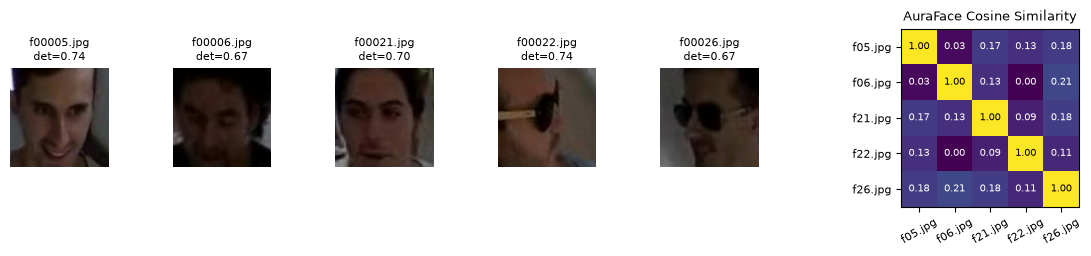

In [6]:
ARCFACE_DST = np.array([
    [38.2946, 51.6963],
    [73.5318, 51.5014],
    [56.0252, 71.7366],
    [41.5493, 92.3655],
    [70.7299, 92.2041],
], dtype=np.float32)

def norm_crop_standalone(bgr: np.ndarray, pts5: np.ndarray, size: int = 112) -> np.ndarray:
    M, _ = cv2.estimateAffinePartial2D(pts5.astype(np.float32), ARCFACE_DST, method=cv2.LMEDS)
    if M is None:
        M, _ = cv2.estimateAffinePartial2D(pts5.astype(np.float32), ARCFACE_DST, method=cv2.RANSAC)
    return cv2.warpAffine(bgr, M, (size, size), borderValue=0.0)

def embed_aurafaces(aligned_bgr_list: list[np.ndarray]) -> np.ndarray:
    batch = np.stack([
        ((img[:, :, ::-1].astype(np.float32) - 127.5) / 127.5).transpose(2, 0, 1)
        for img in aligned_bgr_list
    ], axis=0)
    feats = sess_af.run(None, {"data": batch})[0]
    norms = np.linalg.norm(feats, axis=1, keepdims=True) + 1e-12
    return feats / norms

gallery = []
for fn in ["frame_00005.jpg", "frame_00006.jpg", "frame_00021.jpg", "frame_00022.jpg", "frame_00026.jpg"]:
    bgr = cv2.imread(str(REPO_ROOT / "perception" / "models" / "DeepStream-Yolo" / "calib_images" / fn))
    canvas, sc, dx, dy = letterbox_rgb(bgr, 640, 480)
    x = (canvas.astype(np.float32) / 255.0).transpose(2, 0, 1)[None]
    ds_out = sess_ds_fd.run(None, {"images": x})[0][0]
    dets = nvdsparse_yolo_face_cpp_mirror(ds_out, 640, 480, precluster_thresh=0.45)
    assert len(dets) >= 1, f"No face >=0.45 on {fn}"
    sc_det, (fx, fy, fw, fh), mask = dets[0]
    pts = np.stack([(mask.values[0::3] - dx) / sc, (mask.values[1::3] - dy) / sc], axis=1)
    bx1, by1 = max(0, int((fx - dx) / sc)), max(0, int((fy - dy) / sc))
    bx2, by2 = min(bgr.shape[1], int((fx + fw - dx) / sc)), min(bgr.shape[0], int((fy + fh - dy) / sc))
    aligned = norm_crop_standalone(bgr, pts, 112)
    naive = cv2.resize(bgr[by1:by2, bx1:bx2], (112, 112), interpolation=cv2.INTER_LINEAR)
    jittered = cv2.GaussianBlur(aligned, (3, 3), 0.6)
    flipped = aligned[:, ::-1]
    gallery.append((fn, sc_det, aligned, naive, flipped, jittered))

emb_aligned = embed_aurafaces([g[2] for g in gallery])
emb_naive   = embed_aurafaces([g[3] for g in gallery])
emb_flipped = embed_aurafaces([g[4] for g in gallery])
emb_jitter  = embed_aurafaces([g[5] for g in gallery])

sim_matrix = emb_aligned @ emb_aligned.T
same_flip = np.sum(emb_aligned * emb_flipped, axis=1)
same_blur = np.sum(emb_aligned * emb_jitter, axis=1)
naive_vs_aligned = np.sum(emb_aligned * emb_naive, axis=1)
off_diag = sim_matrix[~np.eye(len(gallery), dtype=bool)]

print(f"5-pt aligned same-face mirror cosine : mean={same_flip.mean():.4f} min={same_flip.min():.4f}")
print(f"5-pt aligned same-face blur cosine   : mean={same_blur.mean():.4f} min={same_blur.min():.4f}")
print(f"Naive unaligned crop vs aligned      : mean={naive_vs_aligned.mean():.4f} (alignment gain!)")
print(f"Distinct faces cross-identity cosine : mean={off_diag.mean():.4f} max={off_diag.max():.4f}")
assert same_blur.min() > 0.80 and same_flip.min() > 0.55 and off_diag.max() < same_flip.min()

# Visual gallery + pairwise similarity heatmap
fig = plt.figure(figsize=(11, 4.2))
gs = fig.add_gridspec(1, len(gallery) + 2, width_ratios=[1]*len(gallery) + [0.15, 1.8])
for i, (fn, sc_det, aligned, _, _, _) in enumerate(gallery):
    ax = fig.add_subplot(gs[0, i])
    ax.imshow(cv2.cvtColor(aligned, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{fn.replace('frame_', 'f')}\ndet={sc_det:.2f}", fontsize=8)
    ax.axis("off")
ax_hm = fig.add_subplot(gs[0, -1])
im = ax_hm.imshow(sim_matrix, vmin=0.0, vmax=1.0, cmap="viridis")
labels = [g[0].replace("frame_000", "f") for g in gallery]
ax_hm.set_xticks(range(len(labels))); ax_hm.set_xticklabels(labels, fontsize=8, rotation=30)
ax_hm.set_yticks(range(len(labels))); ax_hm.set_yticklabels(labels, fontsize=8)
for r in range(len(labels)):
    for c in range(len(labels)):
        ax_hm.text(c, r, f"{sim_matrix[r, c]:.2f}", ha="center", va="center", color="white" if sim_matrix[r, c] < 0.65 else "black", fontsize=7)
ax_hm.set_title("AuraFace Cosine Similarity", fontsize=9)
plt.tight_layout(); plt.show()


## 6. Codebase Readiness Verdict & Integration Checklist


In [7]:
print("=" * 72)
print("TASK 5 VERIFICATION SUMMARY (Commercial Replacements)")
print("=" * 72)
print(f"5A Face Detection : face_det_lite (BSD-3-Clause) -> DeepStream wrapper [B,3,480,640] -> [B,4800,15]")
print(f"   Latency (ORT CUDA): b=1 {ms_b1:.2f} ms | b=16 {ms_b16:.2f} ms ({ms_b16/16:.2f} ms/crop)")
print(f"   Codebase fit      : ZERO C++ changes in nvdsparseface_Yolo.cpp when using wrapper ONNX.")
print(f"                       Update config_sgie_face.txt: onnx-file, infer-dims=3;480;640, model-engine-file.")
print(f"                       Update perception/modules/face_detect/__init__.py default engine fallback.")
print(f"5B Face Recognition: fal/AuraFace-v1 glintr100.onnx ONLY (Apache-2.0)")
print(f"   Latency (ORT CUDA): b=1 {af_ms_b1:.2f} ms | b=16 {af_ms_b16:.2f} ms ({af_ms_b16/16:.2f} ms/face)")
print(f"   Similarity signal : blur-same={same_blur.min():.3f}, flip-same={same_flip.min():.3f} vs cross-max={off_diag.max():.3f}")
print(f"   Codebase fit      : Must decouple perception/insightface_pack.py & recognizer.py & customer_faces")
print(f"                       from 5-file buffalo_l FaceAnalysis() (which demands det_10g.onnx / genderage.onnx).")
print(f"                       Use direct onnxruntime.InferenceSession(glintr100.onnx) + 5-pt cv2.warpAffine().")
print("=" * 72)


TASK 5 VERIFICATION SUMMARY (Commercial Replacements)
5A Face Detection : face_det_lite (BSD-3-Clause) -> DeepStream wrapper [B,3,480,640] -> [B,4800,15]
   Latency (ORT CUDA): b=1 6.09 ms | b=16 38.17 ms (2.39 ms/crop)
   Codebase fit      : ZERO C++ changes in nvdsparseface_Yolo.cpp when using wrapper ONNX.
                       Update config_sgie_face.txt: onnx-file, infer-dims=3;480;640, model-engine-file.
                       Update perception/modules/face_detect/__init__.py default engine fallback.
5B Face Recognition: fal/AuraFace-v1 glintr100.onnx ONLY (Apache-2.0)
   Latency (ORT CUDA): b=1 14.15 ms | b=16 85.88 ms (5.37 ms/face)
   Similarity signal : blur-same=0.990, flip-same=0.587 vs cross-max=0.211
   Codebase fit      : Must decouple perception/insightface_pack.py & recognizer.py & customer_faces
                       from 5-file buffalo_l FaceAnalysis() (which demands det_10g.onnx / genderage.onnx).
                       Use direct onnxruntime.InferenceSession(glin